# D502 Capstone Project - Jon Taylor

## A Comparison of Reported Pertussis Incidence in U.S. Jurisdictions Before and After the COVID-19 Pandemic

### Project Overview

This notebook presents a quantitative, retrospective observational analysis of publicly available pertussis surveillance data from the Centers for Disease Control and Prevention (CDC) via the National Notifiable Diseases Surveillance System (NNDSS).

The purpose of the analysis is to determine whether reported pertussis incidence differed significantly between two study periods across the 50 U.S. states and the District of Columbia.

Research question: 

Did reported pertussis incidence differ significantly between the pre-pandemic period (2016-2019) and the post-acute-pandemic period (2022-2023) across the 50 U.S. states and the District of Columbia?

### Analytical Approach

The analysis uses annual reported incidence rates per 100,000 population for each jurisdiction. For each jurisdiction, the mean annual rate is calculated separately for the pre-pandemic and post-acute-pandemic periods. The difference between these two means is then used to compare changes within the same jurisdiction.

The years 2020 and 2021 are excluded from the period averages. The analysis uses descriptive statistics, visualizations, and inferential statistical tests to evaluate the magnitude, direction, and statistical significance of the difference. 

The paired-samples t-test is the primary inferential method. The Wilcoxon signed-rank test and exact sign test provide supplementary analyses because the paired differences do not follow a normal distribution. 

### Tools and Libraries

The analysis uses Python and the following libraries: 

- pandas: Importing, cleaning, organizing, and aggregating the surveillance data.
- NumPy: Numerical calculations and statistical computations.
- SciPy: Inferential statistical tests.
- Matplotlib: Data visualization.
- Jupyter Notebook: Combining code, results, visualizations, and explanatory documentation.

### Interpretation and Limitations

The outcome measured in this project is reported pertussis incidence, not the incidence of all infections in the population. The pertussis surveillance case definition changed effective January 1, 2020, which limits direct comparability between the two study periods. The retrospective observational design does not establish that the COVID-19 pandemic caused any observed differences. 

The notebook documents the data preparation, statistical methods, results, and visualizations used to address the research question. 

## 1. Data Loading and Initial Inspection

### 1.1 Importing Libraries and Loading the Data

The analysis begins by importing the libraries for data preparation, statistical analysis, and visualization. 

The original CDC NNDSS annual summary data are stored in a CSV file covering 2016 through 2023. The file is loaded into a pandas DataFrame for inspection and preparation. A file existence check is performed before importing the data ensuring the notebook produces a clear error if the expected CSV file is unavailable.

The original dataset is retained separately from the cleaned dataset so that the preparation steps can be reproduced and the source data remain unchanged. 

In [14]:
from pathlib import Path 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from scipy import stats 

# import data
file_path = Path('NNDSS_Annual_Summary_Data_2016-2023_Pertussis.csv')

if not file_path.exists():
    raise FileNotFoundError(f"CSV file not found: {file_path.resolve()}")

df = pd.read_csv(file_path)

# display information about the dataset
print('Dataset shape: ', df.shape)
display(df.head())
df.info()

Dataset shape:  (599, 10)


,Notes,Disease,Disease Code,Year,Year Code,Regions/States,Regions/States Code,Case Count,Population for Published Rate,Published Rate
0,NaN,Pertussis,10190.0,2016.0,2016.0,United States,U.S.,17972,323127513,5.56
1,NaN,Pertussis,10190.0,2016.0,2016.0,New England,REGION1,998,14735525,6.77
2,NaN,Pertussis,10190.0,2016.0,2016.0,Connecticut,09,96,3576452,2.68
3,NaN,Pertussis,10190.0,2016.0,2016.0,Maine,23,259,1331479,19.45
4,NaN,Pertussis,10190.0,2016.0,2016.0,Massachusetts,25,202,6811779,2.97


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 599 entries, 0 to 598
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Notes                          47 non-null     object 
 1   Disease                        552 non-null    object 
 2   Disease Code                   552 non-null    float64
 3   Year                           552 non-null    float64
 4   Year Code                      552 non-null    float64
 5   Regions/States                 552 non-null    object 
 6   Regions/States Code            552 non-null    object 
 7   Case Count                     552 non-null    object 
 8   Population for Published Rate  552 non-null    object 
 9   Published Rate                 552 non-null    object 
dtypes: float64(3), object(7)
memory usage: 46.9+ KB


### 1.2 Examining the Original Dataset

After loading the CSV file, the dataset is examined to understand its structure and identify potential data-quality issues before making any changes.

The inspection includes:

- Column names: Identify the available fields and confirm which columns contain the information needed for the analysis.
- Missing values: Determine whether any columns contain incomplete records. 
- Records by year: Examine how many rows are associated with each year, including rows without a year value.
- Sample records: Review the first and last records to understand the format and identify documentation or other non-data rows.

The original file contains both annual surveillance records and documentation rows. These documentation rows must be distinguished from the actual observations before the data can be analyzed. The initial inspection also helps identify missing values and inconsistencies that require attention during data preparation. 

At this stage, the original data are being examined rather than modified. The next section addresses the cleaning and preparation steps needed to produce a consistent dataset for the jurisdiction-level comparisons. 

In [15]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("\nRows by year:")
display(df.groupby("Year", dropna=False).size().to_frame("Rows"))

print("\nLast 15 rows:")
display(df.tail(15))

Column names:
['Notes', 'Disease', 'Disease Code', 'Year', 'Year Code', 'Regions/States', 'Regions/States Code', 'Case Count', 'Population for Published Rate', 'Published Rate']

Missing values by column:


,Missing values
Notes,552
Disease,47
Disease Code,47
Year,47
Year Code,47
Regions/States,47
Regions/States Code,47
Case Count,47
Population for Published Rate,47
Published Rate,47



Rows by year:


,Rows
Year,
2016.0,69
2017.0,69
2018.0,69
2019.0,69
2020.0,69
2021.0,69
2022.0,69
2023.0,69
NaN,47



Last 15 rows:


,Notes,Disease,Disease Code,Year,Year Code,Regions/States,Regions/States Code,Case Count,Population for Published Rate,Published Rate
584,"(e.g. combining, subsetting, and retirement of...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
585,http://wonder.cdc.gov/wonder/help/nndss.html#R...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
586,"5. Acknowledgment: CDC acknowledges the local,...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
587,case ascertainment sources (e.g. healthcare pr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
588,Notifiable Diseases Surveillance System.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
589,6. Population estimates for calculating incide...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590,the most recent series of estimates available ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
591,with the number of live births in the reportin...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
592,http://wonder.cdc.gov/wonder/help/nndss.html#P...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
593,7. When the national frequency of a disease is...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Cleaning and Preparation

The original dataset contains annual surveillance records along with documentation rows that are not observations. Before conducting the analysis, the data must be cleaned and standardized so that each record represents a valid jurisdiction-year observation. 

The preparation process includes removing documentation rows, converting the relevant fields to numeric data types, combining the two New York reporting areas, and retaining only the 50 states and the District of Columbia. These steps produce a consistent set of jurisdiction-level observations for the study period. 

The original CSV file is not modified. All cleaning and preparation are performed on a copy of the imported DataFrame, preserving the source data for reference.

### 2.1 Standardizing Jurisdiction Records

The first cleaning step removes rows without a year value, as these rows contain CDC documentation rather than annual surveillance observations. The relevant fields (Year, Case Count, Population, and Published Rate) are then converted to numeric data types to support calculations and statistical analyses.

The dataset initially reports New York City and New York State, excluding New York City, as separate reporting areas. These records are combined by year to create a single New York observation. The annual case counts and population denominators are summed, and the combined incidence rate is recalculated as:

Incidence Rate = Total Cases / Total Population *100,000

The national aggregate and reporting areas outside the 50 states and the District of Columbia are excluded. This leaves the jurisdictions defined in the research question while retaining all eight study years.

In [16]:

# Keep rows that contain actual data, excluding the CDC documentation notes.
data = df.dropna(subset=["Year"]).copy()

# Remove columns that contain no values
data = data.dropna(axis=1, how='all')

# Convert numeric columns before performing any calculations.
numeric_cols = [
    "Year",
    "Case Count",
    "Population for Published Rate",
    "Published Rate"
]

for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

area_col = "Regions/States"

# Identify the two separate New York reporting areas.
ny_labels = [
    "New York (excluding New York City)",
    "New York City"
]

ny = data[data[area_col].isin(ny_labels)].copy()

# Verify that both New York records exist for every year.
ny_check = ny.groupby("Year")[area_col].agg(list)

assert len(ny_check) == 8, "Expected New York data for all eight years."
assert all(len(areas) == 2 for areas in ny_check), (
    "Expected two New York reporting areas per year."
)
assert ny["Case Count"].notna().all()
assert ny["Population for Published Rate"].notna().all()

# Combine case counts and populations, then recalculate incidence rate.
ny_combined = (
    ny.groupby("Year", as_index=False)
      .agg({
          "Case Count": "sum",
          "Population for Published Rate": "sum"
      })
)

ny_combined["Published Rate"] = (
    ny_combined["Case Count"]
    / ny_combined["Population for Published Rate"]
    * 100_000
)

ny_combined[area_col] = "New York"

# Remove the separate New York records and insert the combined records.
data = data[~data[area_col].isin(ny_labels)].copy()
data = pd.concat([data, ny_combined], ignore_index=True)

# Retain only the 50 states and District of Columbia.
us_states_and_dc = {
    "Alabama", "Alaska", "Arizona", "Arkansas", "California",
    "Colorado", "Connecticut", "Delaware", "District of Columbia",
    "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana",
    "Iowa", "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland",
    "Massachusetts", "Michigan", "Minnesota", "Mississippi",
    "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
    "New Jersey", "New Mexico", "New York", "North Carolina",
    "North Dakota", "Ohio", "Oklahoma", "Oregon", "Pennsylvania",
    "Rhode Island", "South Carolina", "South Dakota", "Tennessee",
    "Texas", "Utah", "Vermont", "Virginia", "Washington",
    "West Virginia", "Wisconsin", "Wyoming"
}

data[area_col] = data[area_col].str.strip()
data = data[data[area_col].isin(us_states_and_dc)].copy()

# Validate jurisdiction coverage and record uniqueness.
assert data[area_col].nunique() == 51
assert not data.duplicated(subset=["Year", area_col]).any()
assert (data.groupby("Year")[area_col].nunique() == 51).all()

print("Final dataset shape:", data.shape)
print("Jurisdictions:", data[area_col].nunique())
print("Years:", sorted(data["Year"].astype(int).unique()))

print("\nCombined New York records:")
display(
    data.loc[
        data[area_col] == "New York",
        ["Year", "Case Count",
         "Population for Published Rate", "Published Rate"]
    ].sort_values("Year")
)


Final dataset shape: (408, 9)
Jurisdictions: 51
Years: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Combined New York records:


,Year,Case Count,Population for Published Rate,Published Rate
536,2016.0,967.0,19745289.0,4.897371
537,2017.0,691.0,19849399.0,3.481214
538,2018.0,558.0,19542209.0,2.855358
539,2019.0,981.0,19453561.0,5.042779
540,2020.0,217.0,19336776.0,1.122214
541,2021.0,147.0,19336776.0,0.760209
542,2022.0,319.0,19677151.0,1.621170
543,2023.0,1012.0,19571216.0,5.170859


### 2.2 Addressing Missing Incidence Rates

The completeness check identifies observations with missing values in the Published Rate column. A missing published rate does not necessarily mean the underlying case count or population data are unavailable; these records must be examined before deciding how to handle them.

Six observations have missing published rates despite having zero reported cases and positive population denominators. Because dividing zero cases by a positive population yields an incidence rate of zero, these six rates can be set to `0.0` based on the available data. 

This correction is a mathematical calculation rather than statistical imputation. The next step applies the correction only when the case count is zero and the population denominator is positive. Any remaining missing rates are retained for further investigation rather than automatically filled. 

In [17]:
# Find state-year records with missing published rates.
missing_rates = data[data["Published Rate"].isna()]

display(
    missing_rates[
        [
            "Year",
            "Regions/States",
            "Case Count",
            "Population for Published Rate",
            "Published Rate"
        ]
    ].sort_values(["Regions/States", "Year"])
)

print("Records with missing rates:", len(missing_rates))

,Year,Regions/States,Case Count,Population for Published Rate,Published Rate
440,2022.0,Mississippi,0.0,2940057.0,NaN
341,2021.0,Rhode Island,0.0,1057125.0,NaN
408,2022.0,Rhode Island,0.0,1093734.0,NaN
342,2021.0,Vermont,0.0,623347.0,NaN
388,2021.0,Wyoming,0.0,582328.0,NaN
522,2023.0,Wyoming,0.0,584057.0,NaN


Records with missing rates: 6


In [18]:
# Fill missing rates only when the case count is zero
# and the population is known and positive.
zero_case_mask = (
    data["Published Rate"].isna()
    & data["Case Count"].eq(0)
    & data["Population for Published Rate"].gt(0)
)

data.loc[zero_case_mask, "Published Rate"] = 0.0

print("Rates filled:", zero_case_mask.sum())
print("Rates still missing:", data["Published Rate"].isna().sum())

# Display any unresolved records.
display(
    data.loc[
        data["Published Rate"].isna(),
        [
            "Year",
            "Regions/States",
            "Case Count",
            "Population for Published Rate",
            "Published Rate"
        ]
    ]
)

Rates filled: 6
Rates still missing: 0


,Year,Regions/States,Case Count,Population for Published Rate,Published Rate


### 2.3 Validating the Prepared Dataset

After correcting the six missing rates, the prepared dataset is checked for completeness and consistency. The validation checks confirm that: 

- The dataset contains exactly 51 jurisdictions: the 50 states and the District of Columbia.
- Each jurisdiction has one observation for each year from 2016 through 2023. 
- No jurisdiction-year combinations are duplicated.
- Each year contains exactly 51 jurisdiction records.
- No missing values remain in the Published Rate column.

These checks establish that the dataset has the structure required for the paired comparison. The expected result is 408 observations, representing 51 jurisdictions across eight years. 

In [19]:
assert data["Regions/States"].nunique() == 51
assert not data.duplicated(
    subset=["Year", "Regions/States"]
).any()
assert (data.groupby("Year")["Regions/States"].nunique() == 51).all()
assert data["Published Rate"].notna().all()

print("Final dataset shape:", data.shape)
print("Validation passed.")

Final dataset shape: (408, 9)
Validation passed.


### 2.4 Saving the Cleaned Dataset

Once the validation checks pass, the prepared data are saved to a separate CSV file named `cleaned_pertussis_data.csv`. 

Keeping the cleaned dataset separate from the original CDC download preserves the source data and makes the preparation process reproducible. The cleaned file contains one record per jurisdiction per year, with the incidence rate available for every observation. 

The next section uses this validated dataset to calculate the jurisdiction-level averages for the two comparison periods.

In [20]:
# Save validated dataframe as CSV
output_path = Path('cleaned_pertussis_data.csv')

data.to_csv(output_path, index=False)

print(f"Cleaned dataset saved to: {output_path.resolve()}")
print(f"Cleaned dataset columns: {data.columns.tolist()}")

Cleaned dataset saved to: /home/jon_taylor/WGU/D502_Capstone/cleaned_pertussis_data.csv
Cleaned dataset columns: ['Disease', 'Disease Code', 'Year', 'Year Code', 'Regions/States', 'Regions/States Code', 'Case Count', 'Population for Published Rate', 'Published Rate']


## 3. Calculating and Comparing Period Averages

The cleaned dataset contains annual reported pertussis incidence rates for each of the 51 jurisdictions from 2016 through 2023. To address the research question, the analysis calculates a mean annual incidence rate for each jurisdiction during each comparison period. 

The two periods are defined as follows: 

- Pre-pandemic period: 2016-2019, using four annual observations per jurisdiction.
- Post-acute-pandemic period: 2022-2023, using two annual observations per jurisdiction.

The years 2020 and 2021 are excluded from the period averages. Each jurisdiction's mean is calculated using its published annual incidence rates, rather than combining case counts or population denominators across jurisdictions. 

The two period averages are then combined into a comparison dataset containing one paired observation for each jurisdiction. A difference is calculated by subtracting the pre-pandemic mean from the post-acute-pandemic mean:

Difference = Post-acute-pandemic mean - Pre-pandemic mean

A negative difference indicates that the jurisdiction's mean reported incidence rate was lower during the post-acute-pandemic period. A positive difference indicates an increase. 

This paired structure allows the analysis to evaluate changes within the same jurisdictions rather than treating the two periods as independent groups. 

In [21]:

# Define the two comparison periods.
pre_years = [2016, 2017, 2018, 2019]
post_years = [2022, 2023]

# Calculate each jurisdiction's mean annual incidence rate per period.
pre = (
    data[data["Year"].isin(pre_years)]
    .groupby("Regions/States")["Published Rate"]
    .mean()
    .rename("Pre_Mean_Rate")
)

post = (
    data[data["Year"].isin(post_years)]
    .groupby("Regions/States")["Published Rate"]
    .mean()
    .rename("Post_Mean_Rate")
)

# Combine the two period averages into one comparison table.
comparison = pd.concat([pre, post], axis=1)

# Calculate change: post-acute-pandemic period minus pre-pandemic period.
comparison["Difference"] = (
    comparison["Post_Mean_Rate"] - comparison["Pre_Mean_Rate"]
)

# Validate that all 51 jurisdictions have both period averages.
assert comparison.shape[0] == 51
assert comparison.notna().all().all()

print("Jurisdictions compared:", len(comparison))
print("\nOverall mean of jurisdiction-level averages:")
print(f"Pre-pandemic: {comparison['Pre_Mean_Rate'].mean():.3f}")
print(f"Post-acute-pandemic: {comparison['Post_Mean_Rate'].mean():.3f}")
print(f"Mean paired difference: {comparison['Difference'].mean():.3f}")

print("\nJurisdictions with lower later-period rates:",
      (comparison["Difference"] < 0).sum())
print("Jurisdictions with higher later-period rates:",
      (comparison["Difference"] > 0).sum())
print("Jurisdictions with no change:",
      (comparison["Difference"] == 0).sum())

display(comparison.sort_values("Difference"))


Jurisdictions compared: 51

Overall mean of jurisdiction-level averages:
Pre-pandemic: 6.680
Post-acute-pandemic: 1.457
Mean paired difference: -5.223

Jurisdictions with lower later-period rates: 50
Jurisdictions with higher later-period rates: 1
Jurisdictions with no change: 0


,Pre_Mean_Rate,Post_Mean_Rate,Difference
Regions/States,,,
Maine,27.98750,5.575000,-22.412500
Vermont,19.01750,0.230000,-18.787500
Montana,17.96750,2.210000,-15.757500
Wisconsin,14.79000,0.600000,-14.190000
Minnesota,11.70500,0.830000,-10.875000
Idaho,11.69500,1.095000,-10.600000
Alaska,11.97750,1.910000,-10.067500
Washington,8.66000,1.045000,-7.615000
Oregon,8.13000,0.670000,-7.460000


### 3.1 Descriptive Comparison of the Two Periods

The comparison dataset is used to summarize the direction and magnitude of changes across jurisdictions. The analysis calculates the mean of the 51 jurisdiction-level averages for each period and counts how many jurisdictions experienced a decrease, an increase, or no change. 

These summary measures provide an initial description of the observed differences but do not, by themselves, determine whether the mean paired difference is statistically significant. The next section evaluates the paired differences using inferential statistical tests. 

### 3.2 Verifying Period Coverage and Examining Jurisdiction-Level Changes

Before conducting the inferential statistical analysis, the number of annual observations contributing to each jurisdiction's period averages is verified. Each jurisdiction should have four observations for the pre-pandemic period and two observations for the post-acute-pandemic period.

The comparison dataset is also examined to identify the jurisdictions with the largest decreases and increases in mean reported incidence rates. These results provide additional descriptive detail about the variation in changes across jurisdictions.

In [22]:

# Confirm the number of observations per jurisdiction in each period.
pre_counts = (
    data[data["Year"].isin(pre_years)]
    .groupby("Regions/States")["Year"]
    .nunique()
)

post_counts = (
    data[data["Year"].isin(post_years)]
    .groupby("Regions/States")["Year"]
    .nunique()
)

print("Pre-period observations per jurisdiction:")
display(pre_counts.value_counts().sort_index())

print("\nLater-period observations per jurisdiction:")
display(post_counts.value_counts().sort_index())

# Verify the expected number of years for every jurisdiction.
assert (pre_counts == 4).all()
assert (post_counts == 2).all()

print("\nYear-count validation passed.")

# Display the five largest decreases and increases.
print("\nLargest decreases:")
display(comparison.nsmallest(5, "Difference"))

print("\nLargest increases:")
display(comparison.nlargest(5, "Difference"))


Pre-period observations per jurisdiction:


Year
4    51
Name: count, dtype: int64


Later-period observations per jurisdiction:


Year
2    51
Name: count, dtype: int64


Year-count validation passed.

Largest decreases:


,Pre_Mean_Rate,Post_Mean_Rate,Difference
Regions/States,,,
Maine,27.9875,5.575,-22.4125
Vermont,19.0175,0.230,-18.7875
Montana,17.9675,2.210,-15.7575
Wisconsin,14.7900,0.600,-14.1900
Minnesota,11.7050,0.830,-10.8750



Largest increases:


,Pre_Mean_Rate,Post_Mean_Rate,Difference
Regions/States,,,
Nevada,2.38750,2.530000,0.142500
West Virginia,1.45500,1.185000,-0.270000
New York,4.06918,3.396014,-0.673166
Mississippi,1.15500,0.050000,-1.105000
Florida,1.67000,0.325000,-1.345000


## 4. Inferential Statistical Analysis

The descriptive comparison shows the direction and magnitude of changes in reported pertussis incidence. Still, inferential statistical tests are needed to evaluate whether the observed differences provide evidence of a systematic change across jurisdictions. 

The analysis uses a significance level of alpha = 0.05. The primary inferential method is a two-sided paired-samples t-test, which evaluates whether the mean paired difference between the two periods is statistically different from zero.

The hypotheses are: 
- Null Hypothesis (H_0): The population mean paired difference in reported incidence rates is zero (µ_0 = 0).
- Alternative Hypothesis (H_1): The population mean paired difference in reported incidence rates is not zero (µ_0 ≠ 0).

The paired-samples t-test is appropriate because each jurisdiction contributes one mean rate for each period. The analysis therefore evaluates the differences within the same 51 jurisdictions rather than comparing independent groups.

Before interpreting the t-test, the distribution of paired differences is evaluated using the Shapiro-Wilk test. The analysis also includes the Wilcoxon signed-rank test and exact sign test as supplementary methods. These tests provide additional evidence using different distributional assumptions and address whether the observed results are consistent across statistical approaches.

### 4.1 Evaluating the Distribution of Paired Differences

The Shapiro-Wilk test evaluates the null hypothesis that the paired differences are drawn from a normally distributed population. A p-value below the significance level of 0.05 indicates evidence against normality.

The paired-samples t-test evaluates the mean difference, but its inferential reliability depends on the distribution of the paired differences. The Shapiro-Wilk result is therefore considered alongside the histogram and the observed distribution when interpreting the primary test.

Because the paired differences depart from normality, the analysis also uses two supplementary nonparametric tests: 

- Wilcoxon signed-rank test: Evaluates paired differences using their ranks and provides a supplementary assessment of the difference between periods. Its usual location-shift interpretation assumes a symmetric distribution of paired differences; that assumption was not formally tested in this analysis.
- Exact sign test: Evaluates whether positive and negative paired differences occur with equal probability. It focuses on the direction of change rather than the magnitude of the differences and makes fewer distributional assumptions.

The three inferential tests use the same significance threshold of 0.05. Comparing their results provides a broader assessment of the evidence than relying on the paired-samples t-test alone. 

In [23]:

# Paired differences: later-period mean minus pre-pandemic mean.
differences = comparison["Difference"]

# 1. Test normality of the paired differences.
shapiro_result = stats.shapiro(differences)

# 2. Paired t-test on the jurisdiction-level period means.
ttest_result = stats.ttest_rel(
    comparison["Post_Mean_Rate"],
    comparison["Pre_Mean_Rate"]
)

# 3. Wilcoxon signed-rank test.
wilcoxon_result = stats.wilcoxon(
    comparison["Post_Mean_Rate"],
    comparison["Pre_Mean_Rate"],
    alternative="two-sided"
)

# 4. Exact binomial sign test.
n_decreased = (differences < 0).sum()
n_increased = (differences > 0).sum()

sign_result = stats.binomtest(
    n_decreased,
    n=n_decreased + n_increased,
    p=0.5,
    alternative="two-sided"
)

# 5. 95% confidence interval for the mean paired difference.
n = len(differences)
mean_diff = differences.mean()
sd_diff = differences.std(ddof=1)
se_diff = sd_diff / np.sqrt(n)
critical_t = stats.t.ppf(0.975, df=n - 1)

ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

# 6. Cohen's dz effect size for paired observations.
cohens_dz = mean_diff / sd_diff

print("SHAPIRO-WILK NORMALITY TEST")
print(f"W = {shapiro_result.statistic:.4f}, "
      f"p = {shapiro_result.pvalue:.6g}")

print("\nPAIRED T-TEST")
print(f"t({n - 1}) = {ttest_result.statistic:.4f}, "
      f"p = {ttest_result.pvalue:.6g}")

print("\nWILCOXON SIGNED-RANK TEST")
print(f"Statistic = {wilcoxon_result.statistic:.4f}, "
      f"p = {wilcoxon_result.pvalue:.6g}")

print("\nEXACT SIGN TEST")
print(f"Decreases = {n_decreased}, increases = {n_increased}")
print(f"p = {sign_result.pvalue:.6g}")

print("\n95% CONFIDENCE INTERVAL FOR MEAN PAIRED DIFFERENCE")
print(f"Mean difference = {mean_diff:.4f}")
print(f"95% CI = [{ci_low:.4f}, {ci_high:.4f}]")

print("\nCOHEN'S dz")
print(f"d = {cohens_dz:.4f}")


SHAPIRO-WILK NORMALITY TEST
W = 0.8112, p = 1.32835e-06

PAIRED T-TEST
t(50) = -8.1410, p = 1.00738e-10

WILCOXON SIGNED-RANK TEST
Statistic = 1.0000, p = 5.46152e-10

EXACT SIGN TEST
Decreases = 50, increases = 1
p = 4.61853e-14

95% CONFIDENCE INTERVAL FOR MEAN PAIRED DIFFERENCE
Mean difference = -5.2232
95% CI = [-6.5119, -3.9345]

COHEN'S dz
d = -1.1400


### 4.2 Statistical Results

The statistical results include the test statistics, p-values, confidence interval, and effect size for the paired comparison. The paired-samples t-test provides the primary evaluation of the mean difference, while the Wilcoxon signed-rank test and exact sign test provide supplementary assessments. 

The 95% confidence interval estimates the range of plausible values for the population mean paired difference. Cohen's d_z expresses the mean paired difference relative to the standard deviation of the paired differences, providing a standardized measure of effect magnitude. 

The results are interpreted using both statistical significance and the estimated magnitude of the difference. A statistically significant result indicates evidence of a difference between the periods; it does not establish that the COVID-19 pandemic caused the observed change.

| Measure                                                  | Result             |
| :------------------------------------------------------- | -----------------: |
| Jurisdictions                                            |                 51 |
| Pre-pandemic mean incidence rate                         |  6.680 per 100,000 |
| Post-acute-pandemic mean incidence rate                  |  1.457 per 100,000 |
| Mean paired difference                                   | −5.223 per 100,000 |
| Decrease in unweighted means of jurisdiction-level rates |              78.2% |
| 95% CI for mean paired difference                        |   [-6.512, -3.935] |
| Cohen's dz                                               |             -1.140 |
| Jurisdictions with a decrease                            |           50 of 51 |
| Jurisdiction with an increase                            |             Nevada |

Paired t-test

p = 1.00738e-10

Reject the null hypothesis at alpha = 0.05. The mean jurisdiction-level incidence rate differed significantly between the two periods.

Wilcoxon signed-rank test

p = 5.46152e-10

Reject the null under the test's assumptions. The paired differences also show a statistically significant rank-based shift.

Exact sign test

p = 4.61853e-14

Reject the null of equally likely increases and decreases. Fifty jurisdictions decreased and one slightly increased.

Shapiro-Wilk normality test

p = 1.32835e-06

Reject normality of the paired differences. Interpret the paired t-test and its confidence interval with this limitation in mind. The Wilcoxon and sign tests provide complementary evidence of a difference between the periods.

## Visualizations

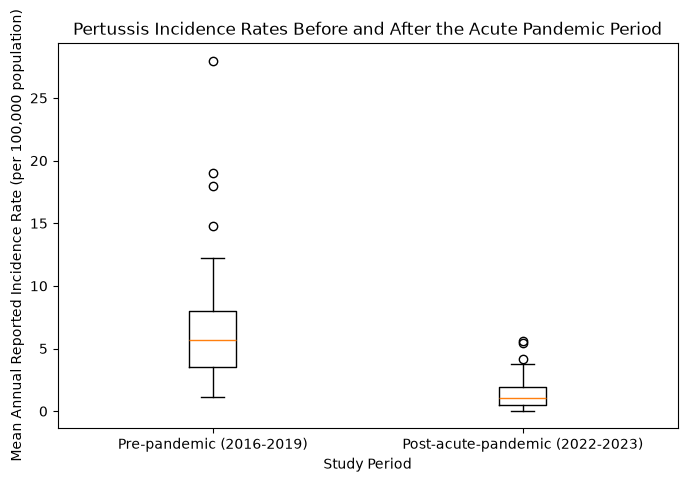

In [24]:
plt.figure(figsize=(8,5))

plt.boxplot(
    [
        comparison["Pre_Mean_Rate"],
        comparison["Post_Mean_Rate"]
    ],
    tick_labels=['Pre-pandemic (2016-2019)', 'Post-acute-pandemic (2022-2023)']
)

plt.title("Pertussis Incidence Rates Before and After the Acute Pandemic Period")
plt.ylabel("Mean Annual Reported Incidence Rate (per 100,000 population)")
plt.xlabel("Study Period")

plt.show()

Figure 1. Distribution of jurisdiction-level mean annual reported pertussis incidence rates for the pre-pandemic period (2016–2019) and post-acute-pandemic period (2022–2023). Each box represents the distribution of mean rates across the 51 jurisdictions. The post-acute-pandemic period shows a lower median and less variability in reported incidence.

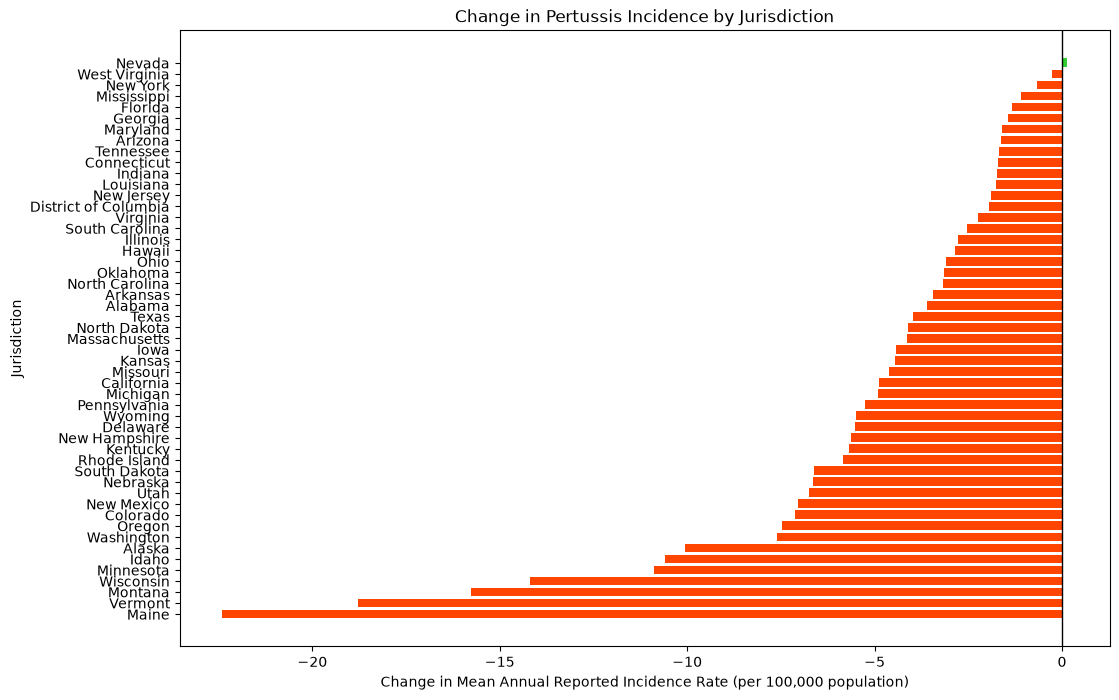

In [25]:
differences = comparison["Difference"].sort_values()

bar_colors = [
    "orangered" if value < 0 else "limegreen"
    for value in differences.values
]

plt.figure(figsize=(12, 8))

plt.barh(differences.index, differences.values, color=bar_colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Change in Pertussis Incidence by Jurisdiction")
plt.xlabel("Change in Mean Annual Reported Incidence Rate (per 100,000 population)")
plt.ylabel("Jurisdiction")
plt.show()

Figure 2. Change in Pertussis Incidence by Jurisdiction. Bars show the difference between each jurisdiction's 2022 - 2023 and 2016 - 2019 average annual incidence rates. Negative values indicate decreases; positive values indicate increases. Fifty jurisdictions had lower average rates in the post-acute-pandemic  period, while one had a slight increase.

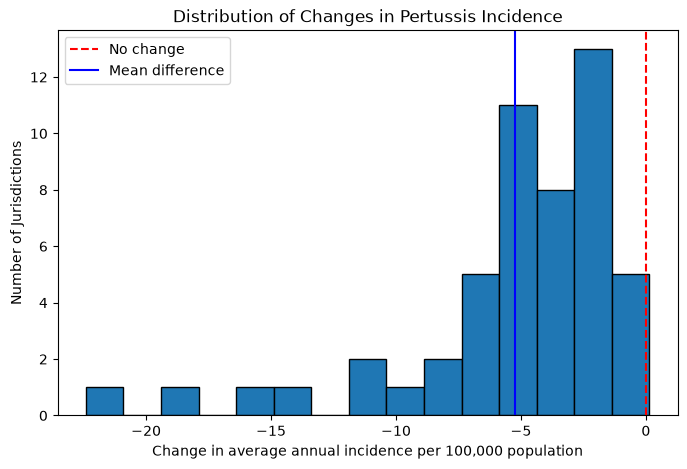

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(comparison['Difference'], bins=15, edgecolor='black')
plt.axvline(0, color='red', linestyle='--', label='No change')
plt.axvline(
    comparison["Difference"].mean(),
    color='blue',
    linestyle='-',
    label='Mean difference'
)

plt.title("Distribution of Changes in Pertussis Incidence")
plt.xlabel("Change in average annual incidence per 100,000 population")
plt.ylabel("Number of Jurisdictions")
plt.legend()
plt.show()

Figure 3. Distribution of Changes in Pertussis Incidence. The histogram displays jurisdiction-level differences in average incidence rates, calculated as post-acute-pandemic average minus the pre-pandemic average. Most differences are negative, with a long tail toward larger decreases. Reference lines indicate zero change and the mean difference. 

## 5. Results and Interpretation

The analysis found a substantial difference in reported pertussis incidence between the pre-pandemic period (2016-2019) and the post-acute-pandemic period (2022-2023). Across the 51 jurisdictions, the mean of the jurisdiction-level average annual incidence rates decreased from 6.680 to 1.457 cases per 100,000 population. This represents a 78.2% decrease in the unweighted mean of the jurisdiction-level rates. 

The mean paired difference was -5.223 cases per 100,000 population, indicating that reported incidence was lower during the post-acute-pandemic period. Fifty of the 51 jurisdictions experienced a decrease, while Nevada was the only jurisdiction with an increase. 

The paired-samples t-test found a statistically significant difference between the two periods (t = -8.141, df = 50, p < 0.001). The 95% confidence interval for the mean paired differences ranged from -6.512 to -3.935 cases per 100,000 population. The negative interval indicates that the decrease was not limited to the observed sample of jurisdictions. 

The supplementary Wilcoxon signed-rank and exact sign tests also found statistically significant differences (p < 0.001 for both tests). These results provide additional support for the conclusion that reported pertussis incidence was generally lower during the post-acute-pandemic period. 

### 5.1 Interpretation of the Visualizations

The three visualizations provide complementary perspectives on the observed changes.

Figure 1 compares the distribution of jurisdiction-level mean annual incidence rates for the two periods. The lower median and narrower distribution in the post-acute-pandemic period indicate that reported incidence decreased across most jurisdictions and that the jurisdiction-level rates were less variable during that period.

Figure 2 displays the difference between the two period averages for each jurisdiction. The predominance of negative bars illustrates that 50 jurisdictions experienced decreases. Nevada's positive bar indicates the only jurisdiction to increase. 

Figure 3 shows the distribution of the paired differences. Most observations fall below zero, confirming that decreases were much more common than increases. The distribution also has a tail extending toward larger negative differences, indicating that some jurisdictions experienced substantially greater decreases than others. 

Taken together, the numerical results and visualizations show a consistent pattern: reported pertussis incidence was substantially lower across U.S. jurisdictions during 2022-2023 than during 2016-2019. 

## 6. Limitations and Considerations

Several limitations should be considered when interpreting the results of this analysis.

### 6.1 Changes in Pertussis Surveillance and Case Definitions

The CDC pertussis surveillance case definition changed effective January 1, 2020. Because the pre-pandemic period (2016-2019) and post-acute-pandemic period (2022-2023) fall on opposite sides of this change, differences in reported incidence may partly reflect changes in case classification and surveillance practices rather than changes in the underlying occurrence of pertussis alone.

The analysis uses reported surveillance data and therefore measures reported pertussis incidence, not the total number of infections in each jurisdiction. Cases that were not diagnosed, tested, or reported are not represented in the dataset.

### 6.2 Exclusion of 2020 and 2021

The years 2020 and 2021 were excluded from the period averages because they represent the acute phase of the COVID-19 pandemic. This approach separates the pre-pandemic baseline from the post-acute-pandemic comparison period. However, excluding these years also means that the analysis does not describe the full trajectory of reported pertussis incidence during the pandemic or the timing of any changes.

### 6.3 Jurisdiction-Level Comparisons

Each jurisdiction contributes equally to the overall comparison, regardless of population size. The reported period means are therefore unweighted averages of jurisdiction-level incidence rates rather than population-weighted national incidence rates. This approach supports comparisons across jurisdictions but does not represent the average incidence experienced by an individual across the entire U.S. population.

Combining New York City and New York State excluding New York City was necessary to produce one observation for New York, consistent with the study's definition of 51 jurisdictions. Although the combined rates were recalculated using summed case counts and population denominators, this aggregation removes the ability to examine New York City separately.

### 6.4 Statistical and Causal Limitations

The Shapiro-Wilk test indicated that the paired differences departed from a normal distribution. Although the paired-samples t-test was retained as the primary analysis, its results were interpreted alongside the Wilcoxon signed-rank test and exact sign test. The Wilcoxon signed-rank test also relies on a symmetry assumption for its usual location-shift interpretation, and that assumption was not formally evaluated.

Finally, this retrospective observational analysis identifies differences in reported incidence between two periods but cannot establish that the COVID-19 pandemic caused those differences. Other changes in disease transmission, healthcare utilization, diagnostic testing, reporting practices, and population behavior may also have contributed to the observed pattern.

## 7. Conclusion

This analysis evaluated whether reported pertussis incidence differed between the pre-pandemic period (2016-2019) and the post-acute-pandemic period (2022-2023) across the 50 U.S. states and the District of Columbia.

The results provide strong statistical evidence of a difference between the two periods. The mean of the jurisdiction-level average annual incidence rates decreased from 6.680 to 1.457 cases per 100,000 population, representing a 78.2% decrease in the unweighted mean. The mean paired difference was −5.223 cases per 100,000 population, and 50 of the 51 jurisdictions experienced a decrease.

The paired-samples t-test identified a statistically significant difference, and the supplementary Wilcoxon signed-rank and exact sign tests supported the same conclusion. The consistency of these findings across the jurisdictions indicates that the decrease was widespread rather than limited to a small number of locations.

The analysis therefore supports the conclusion that reported pertussis incidence was significantly lower during the post-acute-pandemic period than during the pre-pandemic period. However, changes in the pertussis case definition, surveillance and reporting practices, and other factors limit direct comparisons between the periods. The observational design also does not establish that the COVID-19 pandemic caused the observed decrease.

Overall, this project demonstrates how publicly available disease surveillance data, data preparation techniques, descriptive analysis, inferential statistical testing, and visualization can be combined to investigate changes in reported disease incidence across U.S. jurisdictions.